# Chapter 9: Text Processing and Multiclass Classification

*Summary notebook untuk **scikit-learn Cookbook, Third Edition** (John Sukup, Packt 2025) — Chapter 9.*

Bab ini membahas cara mengubah teks menjadi fitur numerik, membangun model klasifikasi teks, menangani klasifikasi multikelas, dan mengevaluasi hasilnya. Contoh menggunakan kumpulan kalimat kecil yang ditulis langsung di notebook agar dapat dijalankan tanpa mengunduh dataset eksternal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

import sklearn
print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version: {np.__version__}")

scikit-learn version: 1.8.0
NumPy version: 2.3.5


> **Catatan versi.** Buku menargetkan scikit-learn 1.5+. Notebook ini menggunakan API umum dari `sklearn.feature_extraction.text`, `sklearn.pipeline`, `sklearn.naive_bayes`, `sklearn.svm`, dan `sklearn.linear_model`. Hasil metrik dapat berubah jika versi pustaka atau data diubah.

## 1. Introduction to Text Processing

### Ringkasan

Algoritma machine learning umumnya membutuhkan fitur numerik, sedangkan dokumen berisi kata dan kalimat. **Text processing** menyiapkan teks agar dapat dipelajari model, misalnya dengan merapikan huruf, menghapus tanda baca yang tidak diperlukan, dan memecah teks menjadi token.

Alur umum:
1. Siapkan teks dan label.
2. Lakukan preprocessing sesuai kebutuhan.
3. Ubah teks menjadi representasi numerik (*vectorization*).
4. Latih model menggunakan fitur dan label.

In [2]:
texts = [
    "Aplikasi ini sangat bagus dan mudah digunakan",
    "Layanan sangat cepat dan membantu",
    "Saya suka fitur baru aplikasi ini",
    "Aplikasi sering error dan sulit digunakan",
    "Layanan lambat dan mengecewakan",
    "Fitur ini buruk dan tidak membantu",
    "Pengiriman cepat dan produk bagus",
    "Produk rusak dan kualitas buruk",
    "Pengalaman sangat memuaskan",
    "Pengalaman mengecewakan dan lambat",
    "Antarmuka mudah dipahami",
    "Aplikasi membingungkan dan sering error",
    "Film ini sangat menarik dan bagus",
    "Film membosankan dan ceritanya buruk",
    "Musik ini indah dan menyenangkan",
    "Musik berisik dan tidak menyenangkan",
    "Makanan lezat dan pelayanannya cepat",
    "Makanan dingin dan pelayanan lambat",
    "Kamera menghasilkan foto yang tajam",
    "Kamera rusak dan hasil foto buruk",
    "Buku ini informatif dan menarik",
    "Buku membingungkan dan kurang menarik",
    "Paket tiba cepat dan kondisi baik",
    "Paket terlambat dan barang rusak",
]
labels = [
    "positif", "positif", "positif", "negatif", "negatif", "negatif",
    "positif", "negatif", "positif", "negatif", "positif", "negatif",
    "positif", "negatif", "positif", "negatif", "positif", "negatif",
    "positif", "negatif", "positif", "negatif", "positif", "negatif"
]

text_df = pd.DataFrame({"teks": texts, "label": labels})
text_df.head(8)

,teks,label
0,Aplikasi ini sangat bagus dan mudah digunakan,positif
1,Layanan sangat cepat dan membantu,positif
2,Saya suka fitur baru aplikasi ini,positif
3,Aplikasi sering error dan sulit digunakan,negatif
4,Layanan lambat dan mengecewakan,negatif
5,Fitur ini buruk dan tidak membantu,negatif
6,Pengiriman cepat dan produk bagus,positif
7,Produk rusak dan kualitas buruk,negatif


**Membaca hasil.** Setiap baris berisi satu dokumen dan label kelasnya. Dataset ini sengaja kecil untuk demonstrasi alur kerja, bukan untuk menyimpulkan kualitas model pada data dunia nyata. Pada proyek sebenarnya, pastikan label konsisten dan data mewakili variasi bahasa yang akan ditemui model.

In [3]:
import re

def preprocess_text(text):
    """Contoh preprocessing ringan: huruf kecil dan hapus tanda baca."""
    text = text.lower()
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

examples = ["Aplikasi BAGUS!!!", "  Layanan, sangat cepat.  "]
[(item, preprocess_text(item)) for item in examples]

[('Aplikasi BAGUS!!!', 'aplikasi bagus'),
 ('  Layanan, sangat cepat.  ', 'layanan sangat cepat')]

**Interpretasi.** Preprocessing ringan menghasilkan teks yang lebih konsisten. Jangan otomatis menghapus semua kata umum (*stop words*) atau melakukan stemming tanpa mengecek dampaknya: kata seperti “tidak” dapat mengubah polaritas sentimen, dan aturan bahasa Indonesia perlu disesuaikan dengan tujuan.

## 2. Text Vectorization Techniques

### Ringkasan

**Vectorization** mengubah dokumen menjadi vektor numerik. Dua pendekatan dasar:

- `CountVectorizer`: merepresentasikan frekuensi kemunculan token.
- `TfidfVectorizer`: memberi bobot berdasarkan frekuensi kata dalam dokumen dan kelangkaannya di seluruh korpus.

Representasi yang dihasilkan biasanya *sparse matrix*, karena sebagian besar kata tidak muncul di setiap dokumen.

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

sample_texts = [
    "model belajar dari data",
    "data membantu model membuat prediksi",
    "model prediksi menggunakan fitur"
]

count_vectorizer = CountVectorizer()
X_count = count_vectorizer.fit_transform(sample_texts)
count_df = pd.DataFrame(
    X_count.toarray(), columns=count_vectorizer.get_feature_names_out()
)
count_df

,belajar,dari,data,fitur,membantu,membuat,menggunakan,model,prediksi
0,1,1,1,0,0,0,0,1,0
1,0,0,1,0,1,1,0,1,1
2,0,0,0,1,0,0,1,1,1


**Membaca hasil.** Baris adalah dokumen dan kolom adalah token. Angka pada tabel menunjukkan jumlah kemunculan kata di masing-masing dokumen. Karena `CountVectorizer` secara default menormalisasi token menjadi huruf kecil, “Model” dan “model” dianggap token yang sama.

In [5]:
tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(sample_texts)
tfidf_df = pd.DataFrame(
    X_tfidf.toarray(), columns=tfidf_vectorizer.get_feature_names_out()
)
tfidf_df.round(3)

,belajar,dari,data,fitur,membantu,membuat,menggunakan,model,prediksi
0,0.584,0.584,0.445,0.000,0.000,0.000,0.000,0.345,0.000
1,0.000,0.000,0.406,0.000,0.534,0.534,0.000,0.315,0.406
2,0.000,0.000,0.000,0.584,0.000,0.000,0.584,0.345,0.445


**Interpretasi.** Bobot TF-IDF cenderung lebih tinggi untuk kata yang penting pada dokumen tetapi tidak terlalu umum pada seluruh korpus. Nilai ini bukan probabilitas dan tidak langsung menyatakan sentimen atau makna kata.

In [6]:
ngram_vectorizer = CountVectorizer(ngram_range=(1, 2), min_df=1)
X_ngrams = ngram_vectorizer.fit_transform(sample_texts)
print("Jumlah fitur unigram + bigram:", len(ngram_vectorizer.get_feature_names_out()))
print(ngram_vectorizer.get_feature_names_out()[:25])

Jumlah fitur unigram + bigram: 19
['belajar' 'belajar dari' 'dari' 'dari data' 'data' 'data membantu'
 'fitur' 'membantu' 'membantu model' 'membuat' 'membuat prediksi'
 'menggunakan' 'menggunakan fitur' 'model' 'model belajar' 'model membuat'
 'model prediksi' 'prediksi' 'prediksi menggunakan']


**N-grams.** `ngram_range=(1, 2)` membuat fitur unigram (satu kata) dan bigram (dua kata berurutan), sehingga sebagian konteks lokal dapat dipertahankan. Rentang n-gram yang lebih besar dapat memperbanyak fitur dan meningkatkan kebutuhan data serta komputasi.

## 3. Feature Extraction from Text

### Ringkasan

**Feature extraction** menghasilkan fitur yang dapat dipakai model. Untuk teks, fitur dapat berasal dari token tunggal, frasa, bobot TF-IDF, atau metadata yang relevan. Pilihan fitur memengaruhi dimensi matriks, interpretabilitas, dan kinerja model.

Penting: untuk menghindari *data leakage*, vectorizer harus dipelajari dari data latih saja. `Pipeline` membantu menggabungkan vectorizer dan model sehingga proses tersebut dilakukan dengan benar saat cross-validation.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

X_train_text, X_test_text, y_train, y_test = train_test_split(
    text_df["teks"], text_df["label"],
    test_size=0.25, random_state=42, stratify=text_df["label"]
)

text_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])
text_pipeline.fit(X_train_text, y_train)
y_pred = text_pipeline.predict(X_test_text)
print("Akurasi:", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred, zero_division=0))

Akurasi: 1.0
              precision    recall  f1-score   support

     negatif       1.00      1.00      1.00         3
     positif       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



**Membaca hasil.** Akurasi adalah proporsi prediksi yang benar. `classification_report` menampilkan precision, recall, dan F1-score. Karena jumlah data sangat sedikit, hasil dapat berubah besar hanya karena satu atau dua contoh; gunakan data yang lebih banyak dan evaluasi silang sebelum mengambil keputusan.

In [8]:
# Lihat fitur yang dibentuk oleh vectorizer setelah pipeline dilatih.
vectorizer_fitted = text_pipeline.named_steps["tfidf"]
feature_names = vectorizer_fitted.get_feature_names_out()
print("Jumlah fitur:", len(feature_names))
print("Contoh fitur:", feature_names[:20])

Jumlah fitur: 113
Contoh fitur: ['antarmuka' 'antarmuka mudah' 'aplikasi' 'aplikasi ini'
 'aplikasi membingungkan' 'aplikasi sering' 'bagus' 'bagus dan' 'barang'
 'barang rusak' 'buku' 'buku ini' 'buku membingungkan' 'buruk' 'buruk dan'
 'cepat' 'cepat dan' 'dan' 'dan bagus' 'dan barang']


**Catatan.** Fitur TF-IDF merupakan representasi statistik dari teks, bukan pemahaman bahasa secara mendalam. Periksa apakah fitur menangkap pola yang relevan, dan pertimbangkan variasi ejaan, kata tidak baku, singkatan, atau bahasa campuran pada korpus nyata.

## 4. Implementing Text Classification Models

### Ringkasan

Setelah teks diubah menjadi fitur, beberapa model dapat digunakan untuk klasifikasi teks. Bab ini membandingkan pendekatan umum seperti **Naive Bayes**, **Support Vector Machine (SVM)**, dan **Logistic Regression**.

Untuk teks, model linear sering menjadi baseline yang kuat karena matriks TF-IDF berdimensi tinggi dan jarang (*sparse*). Pemilihan model tetap perlu diuji dengan data dan metrik yang sesuai.

In [9]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42)
}

model_results = []
for name, estimator in models.items():
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("classifier", estimator)
    ])
    pipeline.fit(X_train_text, y_train)
    predictions = pipeline.predict(X_test_text)
    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1 macro": f1_score(y_test, predictions, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(model_results).sort_values("F1 macro", ascending=False)
results_df.round(3)

,Model,Accuracy,F1 macro
0,Naive Bayes,1.0,1.0
1,Linear SVM,1.0,1.0
2,Logistic Regression,1.0,1.0


**Interpretasi.** Tabel membandingkan model pada pembagian data uji yang sama. `F1 macro` menghitung F1 setiap kelas lalu merata-ratakannya tanpa memberi bobot berdasarkan jumlah sampel per kelas. Dataset kecil dapat membuat urutan model tidak stabil; jangan menganggap model terbaik pada satu split pasti terbaik secara umum.

In [10]:
# Contoh prediksi pada teks baru menggunakan pipeline yang sudah dilatih.
example_messages = [
    "aplikasi sangat mudah dan membantu",
    "produk rusak dan pelayanan buruk",
    "pengalaman cepat dan memuaskan"
]

# Gunakan model yang dibuat pada loop terakhir sebagai contoh pipeline final.
# Untuk aplikasi nyata, simpan pipeline yang dipilih berdasarkan validasi.
example_predictions = pipeline.predict(example_messages)
pd.DataFrame({"teks_baru": example_messages, "prediksi": example_predictions})

,teks_baru,prediksi
0,aplikasi sangat mudah dan membantu,positif
1,produk rusak dan pelayanan buruk,negatif
2,pengalaman cepat dan memuaskan,positif


**Praktik yang disarankan.** Pada kode sebelumnya, variabel `pipeline` berisi model yang terakhir diproses dalam loop. Untuk penggunaan nyata, simpan setiap pipeline dalam dictionary dan pilih berdasarkan hasil validasi, bukan berdasarkan data uji. Data uji sebaiknya digunakan hanya untuk evaluasi akhir.

## 5. Multiclass Classification Strategies

### Ringkasan

Klasifikasi multikelas memprediksi satu label dari lebih dari dua kelas. Dua strategi umum adalah:

- **One-vs-Rest (OvR)**: melatih satu classifier untuk setiap kelas, dengan membedakan kelas tersebut dari gabungan kelas lain.
- **One-vs-One (OvO)**: melatih classifier untuk setiap pasangan kelas.

Pada scikit-learn, `OneVsRestClassifier` dan `OneVsOneClassifier` memungkinkan strategi ini diterapkan pada estimator dasar.

In [11]:
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report

# Dataset mini multikelas: kategori topik, bukan sentimen.
topic_texts = [
    "tim mencetak gol di pertandingan sepak bola", "pemain berlatih untuk pertandingan bola",
    "pelatih mengatur strategi tim sepak bola", "klub menang dalam liga sepak bola",
    "program komputer memakai algoritma data", "model machine learning belajar dari data",
    "pengembang menulis kode program komputer", "analisis data memakai model statistik",
    "resep makanan memakai bahan segar", "koki memasak makanan di dapur",
    "restoran menyajikan hidangan lezat", "sayuran segar digunakan untuk resep"
]
topic_labels = ["olahraga"]*4 + ["teknologi"]*4 + ["makanan"]*4

X_topic_train, X_topic_test, y_topic_train, y_topic_test = train_test_split(
    topic_texts, topic_labels, test_size=0.25, random_state=7, stratify=topic_labels
)

def make_topic_pipeline(strategy):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("classifier", strategy(LinearSVC(random_state=7)))
    ])

ovr_model = make_topic_pipeline(OneVsRestClassifier)
ovo_model = make_topic_pipeline(OneVsOneClassifier)
ovr_model.fit(X_topic_train, y_topic_train)
ovo_model.fit(X_topic_train, y_topic_train)
print("OvR predictions:", ovr_model.predict(X_topic_test))
print("OvO predictions:", ovo_model.predict(X_topic_test))

OvR predictions: ['olahraga' 'makanan' 'teknologi']
OvO predictions: ['olahraga' 'makanan' 'teknologi']


**Interpretasi.** OvR membutuhkan kira-kira satu classifier per kelas, sedangkan OvO membangun classifier untuk setiap pasangan kelas. Jumlah model OvO bertambah lebih cepat saat jumlah kelas meningkat. Strategi yang lebih baik bergantung pada estimator, ukuran dataset, dan distribusi kelas.

## 6. Evaluating Text Models

### Ringkasan

Evaluasi model teks menggunakan metrik klasifikasi umum:

- **Precision**: dari prediksi suatu kelas, proporsi yang benar.
- **Recall**: dari seluruh contoh kelas tersebut, proporsi yang ditemukan model.
- **F1-score**: rata-rata harmonik precision dan recall.
- **Confusion matrix**: menunjukkan kelas sebenarnya dibandingkan dengan kelas prediksi.

Untuk masalah multikelas atau dataset yang tidak seimbang, periksa metrik per kelas dan pertimbangkan macro/weighted average, bukan hanya accuracy.

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report

# Evaluasi pipeline klasifikasi sentimen dari bagian 3.
cm = confusion_matrix(y_test, y_pred, labels=["negatif", "positif"])
print("Confusion matrix (baris = aktual, kolom = prediksi):")
print(pd.DataFrame(cm, index=["aktual negatif", "aktual positif"],
                   columns=["prediksi negatif", "prediksi positif"]))
print("\nLaporan klasifikasi:")
print(classification_report(y_test, y_pred, labels=["negatif", "positif"], zero_division=0))

Confusion matrix (baris = aktual, kolom = prediksi):
                prediksi negatif  prediksi positif
aktual negatif                 3                 0
aktual positif                 0                 3

Laporan klasifikasi:
              precision    recall  f1-score   support

     negatif       1.00      1.00      1.00         3
     positif       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



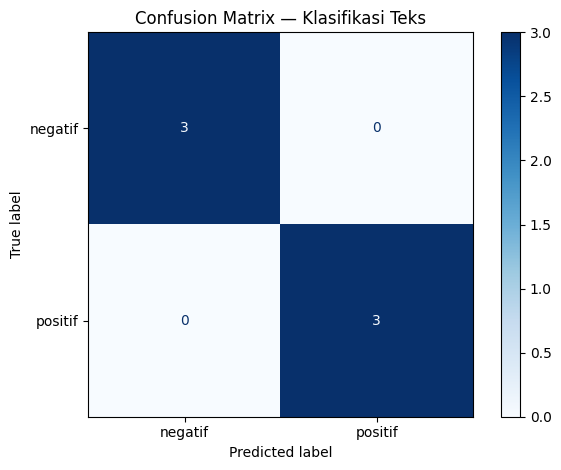

In [13]:
ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["negatif", "positif"]
).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Klasifikasi Teks")
plt.tight_layout()
plt.show()

**Membaca confusion matrix.** Nilai diagonal menunjukkan prediksi yang benar; nilai di luar diagonal menunjukkan kesalahan. Pada dataset kecil, satu kesalahan dapat mengubah precision atau recall secara drastis. Untuk penggunaan nyata, pertimbangkan validasi silang dan uji pada data yang merepresentasikan kondisi operasional.

In [14]:
# Demonstrasi evaluasi lintas validasi pada keseluruhan korpus.
from sklearn.model_selection import StratifiedKFold, cross_validate

cv_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_scores = cross_validate(
    cv_pipeline, text_df["teks"], text_df["label"], cv=cv,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"}
)
print("Accuracy per fold:", np.round(cv_scores["test_accuracy"], 3))
print("Mean accuracy:", round(cv_scores["test_accuracy"].mean(), 3))
print("F1 macro per fold:", np.round(cv_scores["test_f1_macro"], 3))
print("Mean F1 macro:", round(cv_scores["test_f1_macro"].mean(), 3))

Accuracy per fold: [0.875 0.875 0.75 ]
Mean accuracy: 0.833
F1 macro per fold: [0.873 0.873 0.75 ]
Mean F1 macro: 0.832


**Catatan evaluasi.** `cross_validate` menjalankan vectorizer di dalam pipeline pada setiap fold, sehingga kosakata dipelajari dari bagian latih fold tersebut. Dengan dataset yang lebih besar, gunakan lebih banyak fold atau strategi validasi yang sesuai; pastikan dokumen duplikat atau dari sumber yang sama tidak tersebar secara tidak tepat antara train dan test.

## Kesimpulan Chapter 9

1. **Text processing** menyiapkan teks sebelum pemodelan.
2. **CountVectorizer** dan **TfidfVectorizer** mengubah teks menjadi fitur numerik.
3. N-grams dapat menangkap sebagian konteks frasa, tetapi menambah jumlah fitur.
4. Pipeline menggabungkan vectorizer dan estimator sekaligus membantu mencegah *data leakage* saat validasi.
5. Naive Bayes, SVM, dan Logistic Regression merupakan baseline yang layak dibandingkan pada klasifikasi teks.
6. Strategi OvR dan OvO menangani klasifikasi multikelas dengan cara berbeda.
7. Accuracy sebaiknya dilengkapi precision, recall, F1-score, confusion matrix, dan validasi silang.

### Latihan mandiri

1. Tambahkan contoh teks baru dan uji apakah preprocessing mengubah hasil.
2. Bandingkan `CountVectorizer` dengan `TfidfVectorizer` pada split yang sama.
3. Uji `ngram_range=(1, 1)` dan `(1, 2)`, lalu catat jumlah fitur dan F1 macro.
4. Bandingkan Naive Bayes, Linear SVM, dan Logistic Regression menggunakan validasi silang.
5. Buat dataset tiga kelas dengan lebih banyak contoh, lalu bandingkan OvR dan OvO.
6. Identifikasi kelas yang paling sering salah melalui confusion matrix dan jelaskan kemungkinan penyebabnya.